### Notebook basics
- Μπορείτε να εκτελέσετε τον κώδικα κελί-κελί
- για να εκτελέσετε το κελί, πατάτε shift+enter
- με escape+a εισάγετε νέο κελί από πάνω, escape+b νέο κελί από κάτω
- για να τυπώσετε μια μεταβλητη x γράφετε print(x) ή απλά x (όπου x το όνομα της μεταβλητής)
- στην python δεν δηλώνουμε τύπο μεταβλητής, αποδίδεται κατά την εξίωση
- πακέτο numpy (short for Numerical Python) για πράξεις πινάκων

In [112]:
# Tα δεδομένα που θα χρησιμοποιήσουμε είναι από το πακέτο PyHammer, που προσδιορίζει αυτόματα το φασματικό τύπο αστέρων.
# Για το σκοπό αυτό χρησιμοποιεί πρότυπα φάσματα (templates) που θα χρησιμοποιήσουμε και σε αυτήν την άσκηση.
# Ολόκληρο το πακέτο μπορεί να βρεθεί στο https://github.com/BU-hammerTeam/PyHammer
# Κατεβάζουμε μόνο τα 13 αρχεία FITS που χρειαζόμαστε, απευθείας από το GitHub.
#https://github.com/BU-hammerTeam/PyHammer/tree/master/resources
# Προσοχή: το link "github.com/.../blob/..." δίνει ιστοσελίδα (HTML) και όχι το αρχείο. Χρειάζεται το "raw.githubusercontent.com/...".

import os
import urllib.request

URL = "https://raw.githubusercontent.com/BU-hammerTeam/PyHammer/master/resources/templates/"
DATA_DIR = "pyHammer_templates"          # φάκελος όπου αποθηκεύονται τα αρχεία
os.makedirs(DATA_DIR, exist_ok=True)

# Λεξικό: όνομα αστέρα -> όνομα αρχείου στο GitHub
# (τα O, B και A0 δεν έχουν μεταλλικότητα στο όνομα· τα υπόλοιπα είναι νάνοι με [Fe/H] = +0.0)
files = {'O5': 'O5.fits',
         'B0': 'B0.fits',
         'B5': 'B5.fits',
         'A0': 'A0.fits',
         'A6': 'A6_+0.0_Dwarf.fits',
         'F0': 'F0_+0.0_Dwarf.fits',
         'F5': 'F5_+0.0_Dwarf.fits',
         'G0': 'G0_+0.0_Dwarf.fits',
         'G5': 'G5_+0.0_Dwarf.fits',
         'K0': 'K0_+0.0_Dwarf.fits',
         'K5': 'K5_+0.0_Dwarf.fits',
         'M0': 'M0_+0.0_Dwarf.fits',
         'M5': 'M5_+0.0_Dwarf.fits'}

for star in files:
    path = os.path.join(DATA_DIR, files[star])
    if not os.path.isfile(path):                      # κατεβάζουμε μόνο αν δεν υπάρχει ήδη
        urllib.request.urlretrieve(URL + files[star], path)
    print(star, "->", path)

O5 -> pyHammer_templates/O5.fits
B0 -> pyHammer_templates/B0.fits
B5 -> pyHammer_templates/B5.fits
A0 -> pyHammer_templates/A0.fits
A6 -> pyHammer_templates/A6_+0.0_Dwarf.fits
F0 -> pyHammer_templates/F0_+0.0_Dwarf.fits
F5 -> pyHammer_templates/F5_+0.0_Dwarf.fits
G0 -> pyHammer_templates/G0_+0.0_Dwarf.fits
G5 -> pyHammer_templates/G5_+0.0_Dwarf.fits
K0 -> pyHammer_templates/K0_+0.0_Dwarf.fits
K5 -> pyHammer_templates/K5_+0.0_Dwarf.fits
M0 -> pyHammer_templates/M0_+0.0_Dwarf.fits
M5 -> pyHammer_templates/M5_+0.0_Dwarf.fits


In [113]:
# Τι αρχεία κατεβάσαμε στο φάκελο pyHammer_templates;
print(sorted(os.listdir(DATA_DIR)))

['A0.fits', 'A6_+0.0_Dwarf.fits', 'B0.fits', 'B5.fits', 'F0_+0.0_Dwarf.fits', 'F5_+0.0_Dwarf.fits', 'G0_+0.0_Dwarf.fits', 'G5_+0.0_Dwarf.fits', 'K0_+0.0_Dwarf.fits', 'K5_+0.0_Dwarf.fits', 'M0_+0.0_Dwarf.fits', 'M5_+0.0_Dwarf.fits', 'O5.fits']


Σημείωση για μονάδες: μήκος κύματος [ Angstrom ] και ροή [ 10$^{-17}$ erg cm$^{-2}$ s$^{-1}$ Angstrom$^{-1}$ ]

In [115]:
# Τα αρχεία FITS διαβάζονται με τη βιβλιοθήκη astropy. Ένα αρχείο FITS έχει ένα ή περισσότερα μέρη (HDU).
from astropy.io import fits
import numpy as np   # ονοματίζουμε τη βιβλιοθήκη για ευκολία χρήσης

# hdul = fits.open("pyHammer_templates/B0.fits") # Header Data Unit list
hdul = fits.open("pyHammer_templates/B5.fits")
hdul.info()        # 3 μέρη: 0 = σχόλια, 1 = φάσμα, 2 = ιδιότητες του προτύπου


Filename: pyHammer_templates/B5.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1                1 BinTableHDU     16   61618R x 4C   [E, E, E, E]   
  2                1 BinTableHDU     16   3R x 4C   [E, E, E, E]   


In [116]:
# Το HDU 0 έχει μόνο σχόλια: από πόσα φάσματα SDSS/BOSS φτιάχτηκε το πρότυπο
print(repr(hdul[0].header))
print(repr(hdul[1].header))
print(repr(hdul[2].header))
print(repr(hdul[2].data))

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
COMMENT Photometry from 6 objects                                               
COMMENT Template made from 15 Co-added individual BOSS (SDSS) spectra           
XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   16 / length of dimension 1                          
NAXIS2  =                61618 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                   

In [117]:
# HDU 1: το φάσμα. Στήλες: LogLam = log10(λ / Å), Flux, PropErr και Std (σφάλματα της ροής)
spec = hdul[1].data
print(spec.columns.names)

wavelength1 = 10**spec["LogLam"]     # μήκος κύματος σε Å (το αρχείο δίνει log10 του λ)
flux1 = spec["Flux"]                 # ροή σε 1e-17 erg/s/cm^2/Å
PropErr = spec["PropErr"]
Std = spec["Std"]

print(wavelength1[:5])
print(flux1[:5])
print(PropErr[:5])
print(Std[:5])

['LogLam', 'Flux', 'PropErr', 'Std']
[3650.0496 3650.1099 3650.1719 3650.232  3650.2922]
[7.742411 7.790268 7.91669  8.090388 8.266614]
[1.1265665 1.1267736 1.127168  1.1310143 1.1336917]
[1.5018401 1.4797599 1.5501462 1.6665463 1.846289 ]


In [118]:
# HDU 2: ιδιότητες του προτύπου (χρώματα SDSS, και για κάποια πρότυπα Teff και log g)
# Κάθε στήλη έχει 3 τιμές: [μέση τιμή, σφάλμα φωτομετρίας, τυπική απόκλιση των τιμών που προστέθηκαν]
prop = hdul[2].data
print(prop.columns.names)
print(prop)

# Το B0 δεν έχει Teff. Τα πρότυπα F, G, K έχουν:
prop_F0 = fits.open("pyHammer_templates/F0_+0.0_Dwarf.fits")[2].data
print(prop_F0.columns.names)
print("F0: Teff =", prop_F0["Teff"][0], "K, log g =", prop_F0["Log_g"][0])

['u-g', 'g-r', 'r-i', 'i-z']
[(0.20610397, -0.35001597, -0.30597052, -0.20992915)
 (0.01480702,  0.0122942 ,  0.01282588,  0.02920446)
 (0.09548141,  0.02028196,  0.03172848,  0.02833871)]
['u-g', 'g-r', 'r-i', 'i-z', 'Teff', 'Log_g']
F0: Teff = 7585.0635 K, log g = 4.121878


In [119]:
stars_b = {'O5': 50000}
stars_b['G5']=5654.9395 #8000
stars_b['G5']

5654.9395

In [120]:
# Θέλουμε να κάνουμε το ίδιο πράγμα αυτόματα - όχι n φορές για n αστέρια.
# Tα ονόματα των αστέρων, όπως και τη θερμοκρασία τους, που θα μας χρειαστεί παρακάτω, τα οργανώνουμε σε λεξικό.
# Λεξικό = μία λίστα που τα στοιχεία της τα καλούμε με το όνομα.

# Λιστα:
# stars = ["O5","B0","B5","A0","A6","F0","F5","G0","G5","K0","K5","M0","M5"]

# Λεξικό: θερμοκρασίες (K) αστέρων της κύριας ακολουθίας (νάνοι, τάξη V)
# από τον πίνακα των Pecaut & Mamajek 2013, ApJS 208, 9 (έκδοση 2022).
#https://ui.adsabs.harvard.edu/abs/2013ApJS..208....9P/abstract
# Για τα πρότυπα F, G, K θα τις αντικαταστήσουμε παρακάτω με την Teff που δίνει το ίδιο το αρχείο FITS.
stars = {'O5': 41400, 'B0': 31400, 'B5': 15700, 'A0': 9700, 'A6': 7910, 'F0': 7220, 'F5': 6550,
         'G0': 5930, 'G5': 5660, 'K0': 5270, 'K5': 4440, 'M0': 3850, 'M5': 3060}
# Από τη θεωρία, γενικά εύρη θερμοκρασίων (Κ):
# O > 30000, B 30000 – 10000, A 10000 – 7500, F 7500 – 6000, G 6000 – 5200, K 5200 – 3700, M 3700 – 2400

# Παραδειγμα
for i in stars: print(i, stars[i])

O5 41400
B0 31400
B5 15700
A0 9700
A6 7910
F0 7220
F5 6550
G0 5930
G5 5660
K0 5270
K5 4440
M0 3850
M5 3060


In [121]:
# Τώρα μπορούμε να φτιαξουμε ένα λεξικό από διδιάστατους πίνακες,
# ώστε να χρησιμοποιούμε το όνομα του κάθε αστεριού για να βρίσκουμε τα δεδομένα του.
# Σε ένα λεξικό, μπορούμε να προσθέσουμε στοιχεία ως spectra['NewQuantity']=value

spectra = {}  # κενό λεξικό

for i in stars:
    hdul = fits.open(os.path.join(DATA_DIR, files[i]))   # το πλήρες path: pyHammer_templates/....fits
    spec = hdul[1].data
    spectra[i] = (10**spec["LogLam"], spec["Flux"])     # [wavelength, flux] για κάθε αστέρι

    # Αν το αρχείο έχει Teff (πρότυπα F, G, K), τη χρησιμοποιούμε αντί για την τιμή του πίνακα
    prop = hdul[2].data
    if "Teff" in prop.columns.names:
        print(f"{i}: Teff από το FITS = {prop['Teff'][0]:.0f} K  (πίνακας: {stars[i]} K)")
        stars[i] = round(float(prop["Teff"][0]))
    else:
        print(f"{i}: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα {stars[i]} K")

O5: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 41400 K
B0: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 31400 K
B5: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 15700 K
A0: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 9700 K
A6: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 7910 K
F0: Teff από το FITS = 7585 K  (πίνακας: 7220 K)
F5: Teff από το FITS = 6260 K  (πίνακας: 6550 K)
G0: Teff από το FITS = 5869 K  (πίνακας: 5930 K)
G5: Teff από το FITS = 5655 K  (πίνακας: 5660 K)
K0: Teff από το FITS = 5444 K  (πίνακας: 5270 K)
K5: Teff από το FITS = 4596 K  (πίνακας: 4440 K)
M0: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 3850 K
M5: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 3060 K


In [122]:
stars

{'O5': 41400,
 'B0': 31400,
 'B5': 15700,
 'A0': 9700,
 'A6': 7910,
 'F0': 7585,
 'F5': 6260,
 'G0': 5869,
 'G5': 5655,
 'K0': 5444,
 'K5': 4596,
 'M0': 3850,
 'M5': 3060}

In [123]:
# Τωρα το εκάστοτε spectra[i] είναι ο διδιαστατος πίνακας των δεδομένων ενός αστεριού, με μία κολώνα για το λ, και μία κολώνα για τη ροή
print(spectra["G0"][0])
print(spectra["G0"][1])

[ 3650.0496  3650.1099  3650.1719 ... 10199.542  10199.71   10199.878 ]
[1.0812869  1.0872079  1.0980517  ... 0.59770465 0.5991986  0.5991986 ]


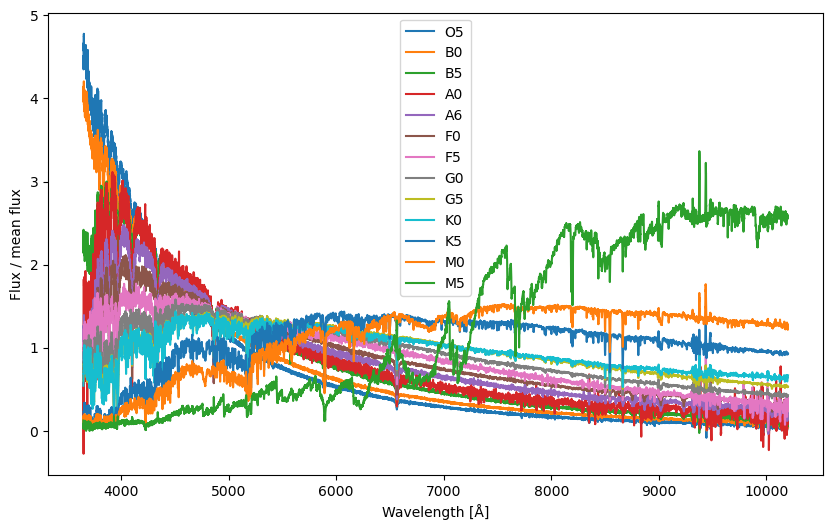

In [124]:
# Ένα πρώτο plot να δουμε τα φάσματα της βιβλιοθήκης συγκρίτικά το ένα με το άλλο
from matplotlib import pyplot as plt

plt.figure(figsize=(10,6))

for i in stars:
    plt.plot(spectra[i][0], spectra[i][1]/np.mean(spectra[i][1]), label=i)
    #plt.plot(spectra[i][0], spectra[i][1], label=i)# Mπορούμε να τα πλοτάρουμε κανονικοποιημένα / μέση τιμη

plt.xlabel("Wavelength [Å]")
plt.ylabel("Flux / mean flux")
plt.legend()


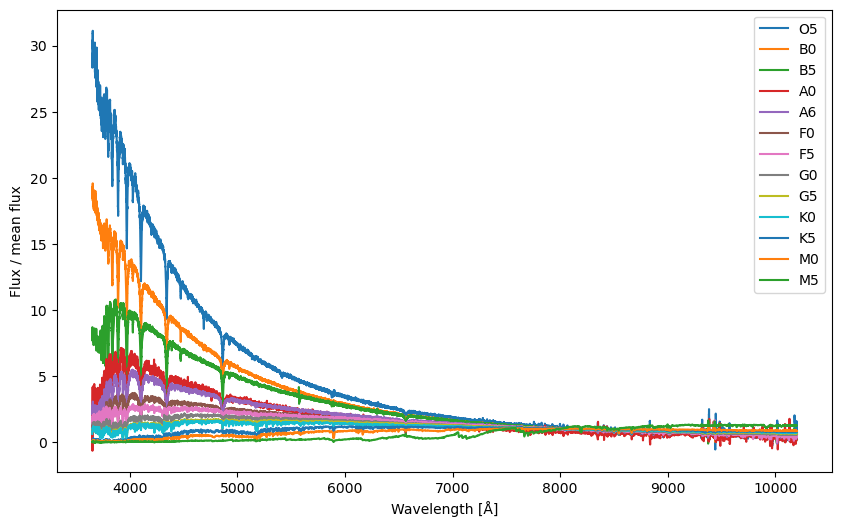

In [125]:
# Ένα πρώτο plot να δουμε τα φάσματα της βιβλιοθήκης συγκρίτικά το ένα με το άλλο
from matplotlib import pyplot as plt

plt.figure(figsize=(10,6))

for i in stars:
    #plt.plot(spectra[i][0], spectra[i][1]/np.mean(spectra[i][1]), label=i)
    plt.plot(spectra[i][0], spectra[i][1], label=i)# Mπορούμε να τα πλοτάρουμε κανονικοποιημένα / μέση τιμη

plt.xlabel("Wavelength [Å]")
plt.ylabel("Flux / mean flux")
plt.legend()


In [126]:
# Θέλουμε να εστιάσουμε σε κάποια γραμμή απορρόφησης ανά αστερι. Εδώ δίνονται τα κεντρικά μήκη κύματος βασικων φασματικών γραμμών.
# Μπορείτε να προσθέσετε γραμμές κατά το δοκούν.

# Γραμμή απορρόφησης <-> μήκος κύματος (Α) + ευρος συνεχούς πάλι εν είδει λεξικού
lines = {
    "Ha":   {"lam": 6562.8,  "cont_left": [6505,6530],  "cont_right": [6620,6645]},      # Balmer a (2→3)
    "Hb":   {"lam": 4861.3,  "cont_left": [4780,4820],  "cont_right": [4920,4950]},      # Balmer a (2→4)
    "Hg":   {"lam": 4340.5,  "cont_left": [4250,4290],  "cont_right": [4390,4440]},      # Balmer a (2→5)
    "Hd":   {"lam": 4101.7,  "cont_left": [4020,4060],  "cont_right": [4150,4190]},      # Balmer a (2→6)
    "Pa7":  {"lam": 10049,   "cont_left": [10025,10030],"cont_right": [10075,10120]},    # Paschen δ (3→7)
   }


(0.9249684810638428, 1.4996269941329956)

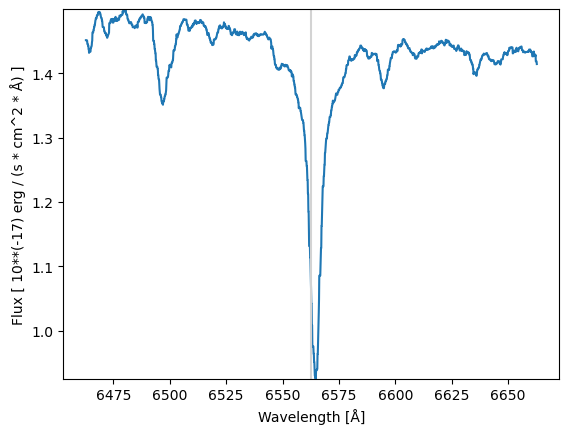

In [127]:
# Ας εστιάσουμε σε κάποια γραμμή απορρόφησης για κάποιο αστερι
# θα χρειαστεί να τρέξετε τον κώδικα για πολλές γραμμές κι αστέρια.

selected_star="G0"
selected_line = "Ha"

wavelength_init=spectra[selected_star][0]
flux_init=spectra[selected_star][1]

central_l= lines[selected_line]["lam"] # επιλεχθέν μήκος κύματος (διαλέγετε από παραπάνω λεξικό ή απλά βάλετε την τιμή με το χέρι σε Α)
dl = 100                               # βρείτε κατάλληλο εύρος του κομμενου φάσματος (σε A) γύρω από τη γραμμή που να ξεπερνάει (αρκετα)
                                       # τη διακριτική ικανότητα του οργάνου και να δίνει καλή μετρηση του συνεχούς.

# πινακας με True / False για τη συνθηκη
selected_range = (wavelength_init >= central_l-dl) & (wavelength_init <= central_l+dl)

# αντικατάσταση των πινάκων με νεους πίνακες, που εχουν μονο τις τιμές εκεί όπου η συνθήκη είναι True.
wavelength = wavelength_init[selected_range]
flux = flux_init[selected_range]

plt.plot(wavelength, flux)
plt.axvline(central_l,color='lightgrey')
plt.xlabel("Wavelength [Å]")
plt.ylabel("Flux [ 10**(-17) erg / (s * cm^2 * Å) ]")
plt.ylim(min(flux),max(flux))


(0.7711168527603149, 1.5715422630310059)

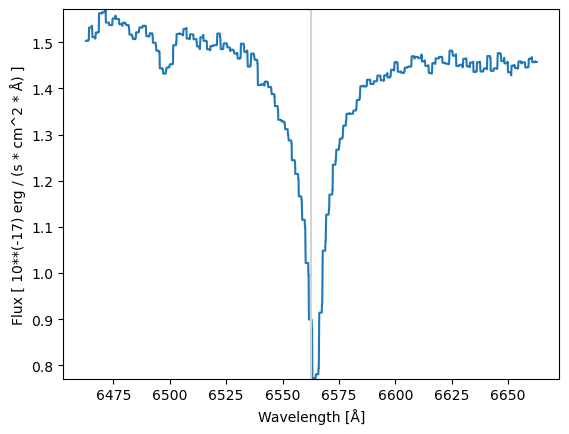

In [128]:
# Ας εστιάσουμε σε κάποια γραμμή απορρόφησης για κάποιο αστερι
# θα χρειαστεί να τρέξετε τον κώδικα για πολλές γραμμές κι αστέρια.

selected_star="F0"
selected_line = "Ha"

wavelength_init=spectra[selected_star][0]
flux_init=spectra[selected_star][1]

central_l= lines[selected_line]["lam"] # επιλεχθέν μήκος κύματος (διαλέγετε από παραπάνω λεξικό ή απλά βάλετε την τιμή με το χέρι σε Α)
dl = 100                               # βρείτε κατάλληλο εύρος του κομμενου φάσματος (σε A) γύρω από τη γραμμή που να ξεπερνάει (αρκετα)
                                       # τη διακριτική ικανότητα του οργάνου και να δίνει καλή μετρηση του συνεχούς.

# πινακας με True / False για τη συνθηκη
selected_range = (wavelength_init >= central_l-dl) & (wavelength_init <= central_l+dl)

# αντικατάσταση των πινάκων με νεους πίνακες, που εχουν μονο τις τιμές εκεί όπου η συνθήκη είναι True.
wavelength = wavelength_init[selected_range]
flux = flux_init[selected_range]

plt.plot(wavelength, flux)
plt.axvline(central_l,color='lightgrey')
plt.xlabel("Wavelength [Å]")
plt.ylabel("Flux [ 10**(-17) erg / (s * cm^2 * Å) ]")
plt.ylim(min(flux),max(flux))


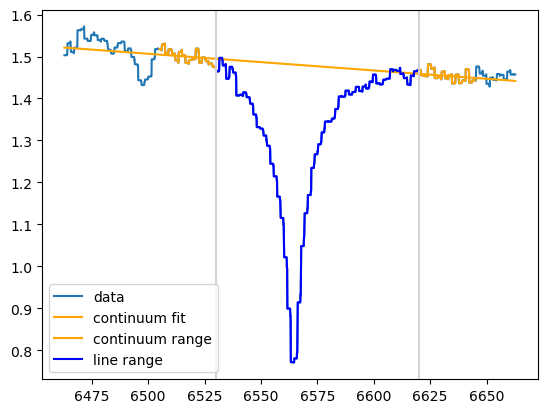

In [129]:
# Τώρα ας ξεχωρίσουμε κι ας φιτάρουμε το συνεχές, χρησιμοποιώντας μια ευθεία, κι ας ορίσουμε το ευρος της γραμμής

# Η μάσκα είναι σε Α. Θα πρέπει να αλλαζει για κάθε φασματική γραμμή.

mask_left =lines[selected_line]["cont_left"]  # η έτοιμη τιμή ή απλά βάζετε ένα δικο σας πίνακα, π.χ., [6505, 6530]
mask_right=lines[selected_line]["cont_right"]

wavelength_left = np.mean(mask_left)    # μέση τιμή του αντίστοιχου εύρους
wavelength_right = np.mean(mask_right)

cont_left  = (wavelength > mask_left[0])  & (wavelength < mask_left[1] ) # πίνακας με True/False εαν τηρείται η συνθηκη.
cont_right = (wavelength > mask_right[0]) & (wavelength < mask_right[1] )
cont = cont_left | cont_right # αριστερό ή δεξί παραθυρο = συνολο συνεχους

flux_left = np.mean( flux[ cont_left ] ) # μέση τιμή της ροής, για pixel στα οποία ισχύει η συνθήκη του μήκους κύματος
flux_right = np.mean( flux[ cont_right] )

slope= (flux_right-flux_left)/(wavelength_right-wavelength_left)
continuum = slope*(wavelength-wavelength_left) + flux_left

plt.plot(wavelength, flux, label='data')
plt.plot(wavelength, continuum, color='orange',label='continuum fit')

in_line = (wavelength > mask_left[1]) & (wavelength < mask_right[0])
plt.plot( wavelength[cont_left], flux[cont_left],color='orange', label='continuum range')
plt.plot( wavelength[cont_right], flux[cont_right],color='orange')
plt.plot( wavelength[in_line], flux[in_line], color='blue',label='line range')
plt.axvline(mask_left[1],color='lightgrey')
plt.axvline(mask_right[0],color='lightgrey')

plt.legend()

In [130]:
# Τώρα η ροή της γραμμής: μετά την αφαίρεση του συνεχούς, αθροίζουμε το εμβαδον y*dx σε όλα τα pixel εντός των ορίων.
# Το βήμα dλ δεν είναι σταθερό (τα pixel είναι ισαπέχοντα σε log λ), οπότε κρατάμε ένα dλ για κάθε pixel.

dlambda = np.gradient(wavelength)

line_flux = np.abs( np.sum((flux[in_line] - continuum[in_line]) * dlambda[in_line]) )  # 1e-17 erg / s /cm^2

print("Flux",line_flux, "*1e-17 erg/s/cm^2")

Flux 12.990797 *1e-17 erg/s/cm^2


In [131]:
# έλεγχος εαν η ανίχνευση ειναι σημαντική (πάνω από το θόρυβο)

# θόρυβος ανά pixel <-> standard deviation
noise_per_pixel = np.std((flux[cont] - continuum[cont]))*np.mean(dlambda[cont])
n_pixels = len( wavelength[in_line] )
noise = np.sqrt(n_pixels)*noise_per_pixel

print("Signal-to-Noise ratio: ",line_flux/noise)

Signal-to-Noise ratio:  342.44834808696777


In [132]:
# Yπολογισμός equivalent width (σε Å).

EW = np.sum((1.0 - flux[in_line] / continuum[in_line]) * dlambda[in_line])

print("Equivalent width:",EW, "Å")

Equivalent width: 8.774414 Å


## Από τα βήματα σε συναρτήσεις
Τα παραπάνω κελιά δείχνουν βήμα-βήμα πώς μετράμε μια γραμμή: κόβουμε το φάσμα, βρίσκουμε το συνεχές, μετράμε ροή, S/N και equivalent width.
Για να μην αντιγράφουμε όλα τα κελιά για κάθε αστέρα και κάθε γραμμή, βάζουμε **τον ίδιο κώδικα** μέσα σε μία συνάρτηση, `measure_line(star, line)`.
Από εδώ και πέρα αλλάζετε μόνο τα ορίσματα. Για νέα γραμμή, προσθέστε μία καταχώρηση στο λεξικό `lines`.

In [134]:
def measure_line(star, line, dl=100, cont_left=None, cont_right=None, plot=True):
    # star: όνομα αστέρα, π.χ. "G0"      line: όνομα γραμμής από το λεξικό lines, π.χ. "Ha"
    # dl: μισό εύρος (Å) του κομμένου φάσματος γύρω από τη γραμμή
    # cont_left, cont_right: παράθυρα συνεχούς [Å, Å]. Αν δεν δοθούν, παίρνουμε αυτά του λεξικού lines.
    if cont_left is None:
        cont_left = lines[line]["cont_left"]
    if cont_right is None:
        cont_right = lines[line]["cont_right"]
    central_l = lines[line]["lam"]

    # 1. κόβουμε το φάσμα γύρω από τη γραμμή
    wavelength_init, flux_init = spectra[star]
    selected_range = (wavelength_init >= central_l-dl) & (wavelength_init <= central_l+dl)
    wavelength = wavelength_init[selected_range]
    flux = flux_init[selected_range]

    # 2. συνεχές: ευθεία από τη μέση ροή στα δύο παράθυρα
    in_left  = (wavelength > cont_left[0])  & (wavelength < cont_left[1])
    in_right = (wavelength > cont_right[0]) & (wavelength < cont_right[1])
    cont = in_left | in_right
    slope = (np.mean(flux[in_right]) - np.mean(flux[in_left])) / (np.mean(cont_right) - np.mean(cont_left))
    continuum = slope*(wavelength - np.mean(cont_left)) + np.mean(flux[in_left])

    # 3. ροή γραμμής, θόρυβος, S/N και equivalent width
    in_line = (wavelength > cont_left[1]) & (wavelength < cont_right[0])
    dlambda = np.gradient(wavelength)
    line_flux = np.abs(np.sum((flux[in_line] - continuum[in_line]) * dlambda[in_line]))
    noise = np.sqrt(np.sum(in_line)) * np.std(flux[cont] - continuum[cont]) * np.mean(dlambda[cont])
    EW = np.sum((1.0 - flux[in_line] / continuum[in_line]) * dlambda[in_line])

    # 4. γράφημα, ίδιο με το βήμα-βήμα παράδειγμα
    if plot:
        plt.figure(figsize=(8,4))
        plt.plot(wavelength, flux, label='data')
        plt.plot(wavelength, continuum, color='orange', label='continuum fit')
        plt.plot(wavelength[in_left],  flux[in_left],  color='orange', lw=3, label='continuum range')
        plt.plot(wavelength[in_right], flux[in_right], color='orange', lw=3)
        plt.axvline(cont_left[1], color='lightgrey')
        plt.axvline(cont_right[0], color='lightgrey')
        plt.xlabel("Wavelength [Å]")
        plt.ylabel("Flux [ 10**(-17) erg / (s * cm^2 * Å) ]")
        plt.title(f"{star}, {line}:  EW = {EW:.2f} Å,  S/N = {line_flux/noise:.0f}")
        plt.legend()
        plt.show()

    print(f"{star} {line}: flux = {line_flux:.3g} *1e-17 erg/s/cm^2,  S/N = {line_flux/noise:.1f},  EW = {EW:.2f} Å")
    return EW

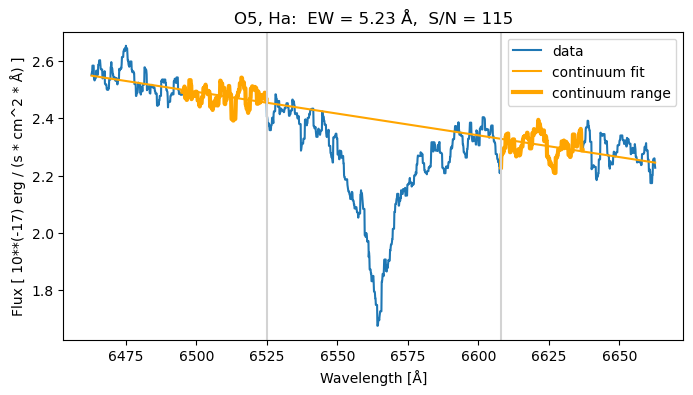

O5 Ha: flux = 12.5 *1e-17 erg/s/cm^2,  S/N = 115.2,  EW = 5.23 Å


5.234788

In [135]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("O5", "Ha")
measure_line("O5", "Ha", cont_left=[6495,6525], cont_right=[6608,6637])

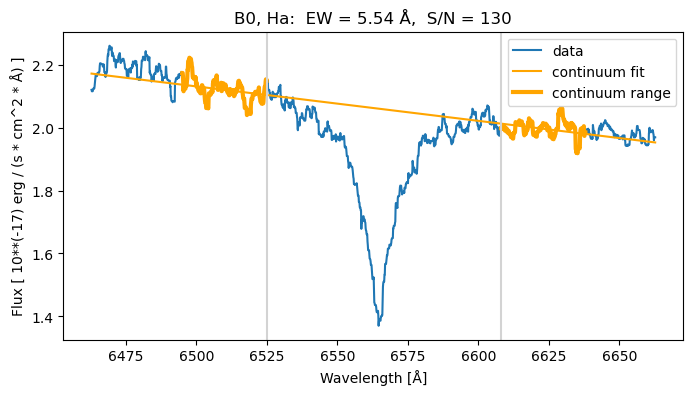

B0 Ha: flux = 11.4 *1e-17 erg/s/cm^2,  S/N = 130.1,  EW = 5.54 Å


5.543976

In [136]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("B0", "Ha", cont_left=[6495,6525], cont_right=[6608,6638])

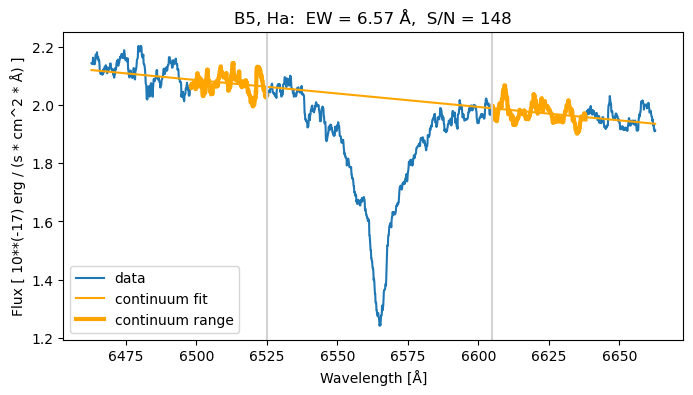

B5 Ha: flux = 13.3 *1e-17 erg/s/cm^2,  S/N = 148.0,  EW = 6.57 Å


6.5694966

In [137]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("B5", "Ha", cont_left=[6498,6525], cont_right=[6605,6638])

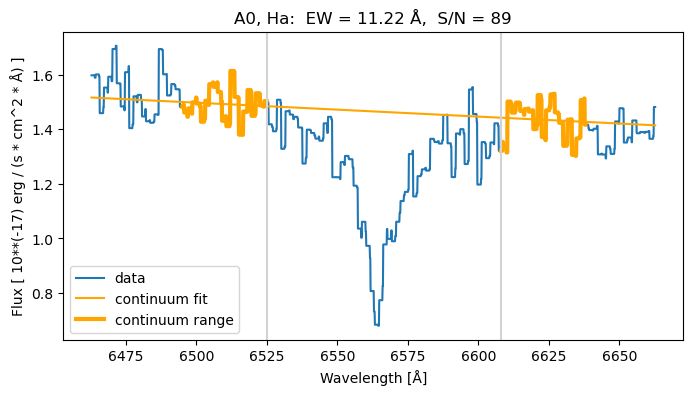

A0 Ha: flux = 16.4 *1e-17 erg/s/cm^2,  S/N = 88.6,  EW = 11.22 Å


11.221692

In [138]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("A0", "Ha", cont_left=[6495,6525], cont_right=[6608,6638])

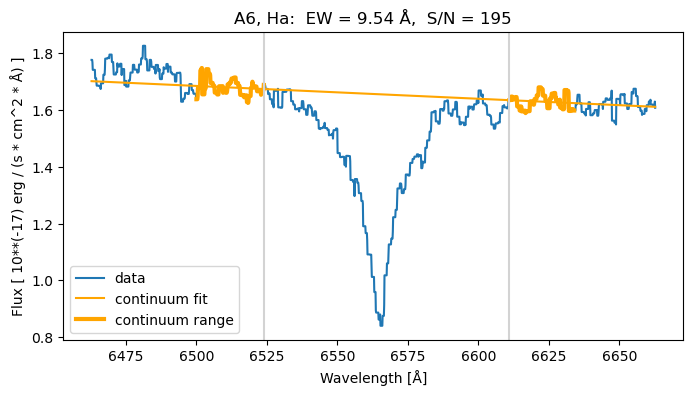

A6 Ha: flux = 15.8 *1e-17 erg/s/cm^2,  S/N = 194.6,  EW = 9.54 Å


9.53578

In [139]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("A6", "Ha", cont_left=[6500,6524], cont_right=[6611,6634])

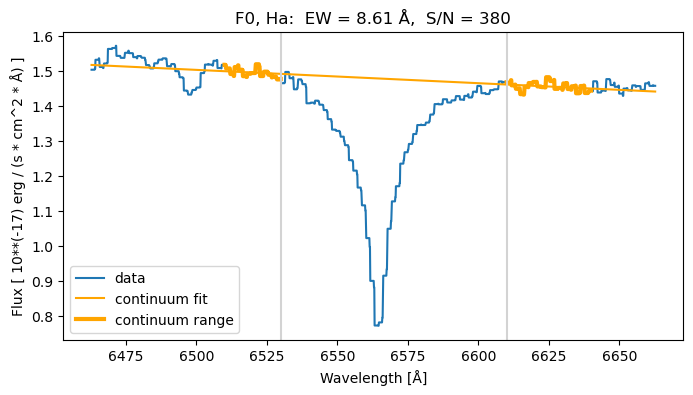

F0 Ha: flux = 12.7 *1e-17 erg/s/cm^2,  S/N = 379.9,  EW = 8.61 Å


8.609358

In [140]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("F0", "Ha", cont_left=[6510,6530], cont_right=[6610,6640])

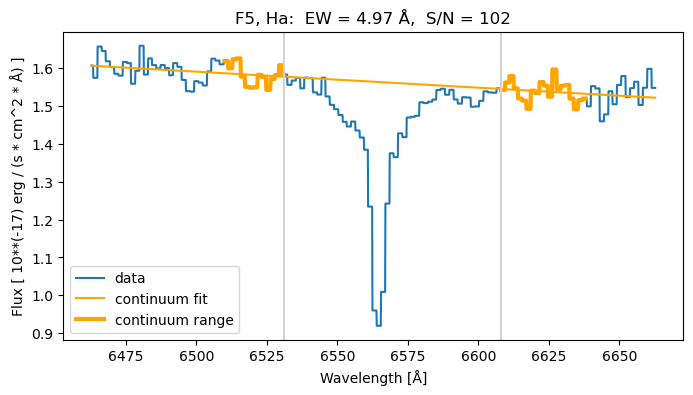

F5 Ha: flux = 7.77 *1e-17 erg/s/cm^2,  S/N = 102.1,  EW = 4.97 Å


4.9677925

In [141]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("F5", "Ha", cont_left=[6510,6531], cont_right=[6608,6638])

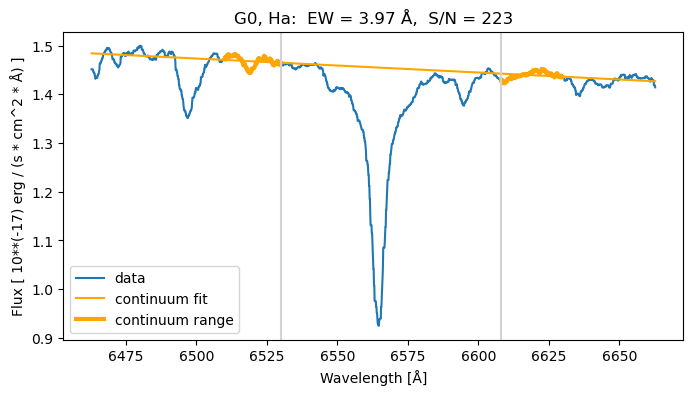

G0 Ha: flux = 5.77 *1e-17 erg/s/cm^2,  S/N = 222.8,  EW = 3.97 Å


3.968531

In [142]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("G0", "Ha", cont_left=[6510,6530], cont_right=[6608,6630])

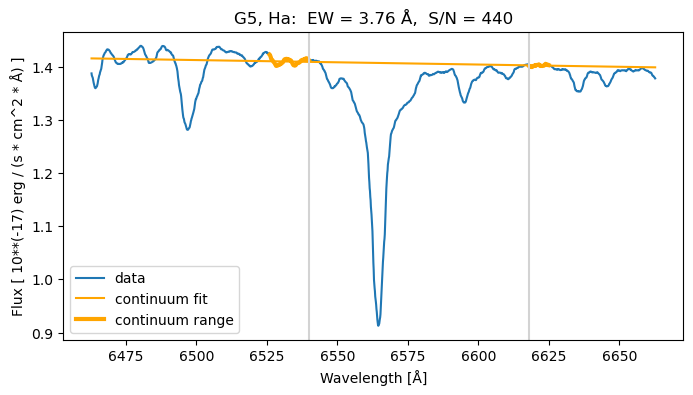

G5 Ha: flux = 5.29 *1e-17 erg/s/cm^2,  S/N = 440.0,  EW = 3.76 Å


3.7640932

In [143]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("G5", "Ha", cont_left=[6526,6540], cont_right=[6618,6625])

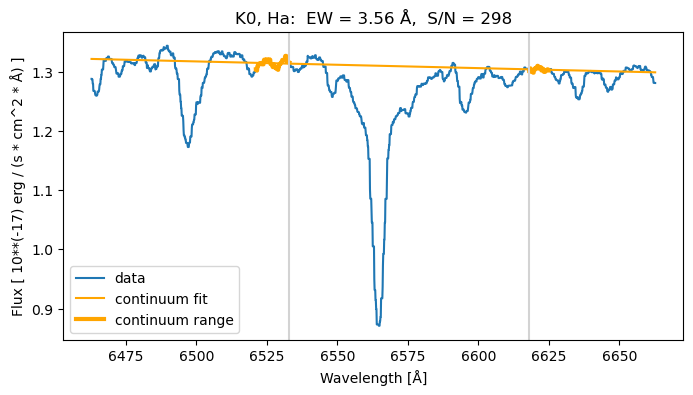

K0 Ha: flux = 4.67 *1e-17 erg/s/cm^2,  S/N = 297.6,  EW = 3.56 Å


3.5639374

In [144]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("K0", "Ha", cont_left=[6521,6533], cont_right=[6618,6625])

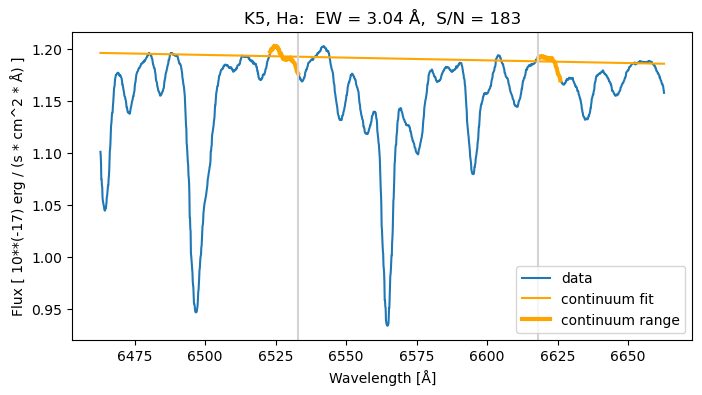

K5 Ha: flux = 3.62 *1e-17 erg/s/cm^2,  S/N = 183.0,  EW = 3.04 Å


3.042613

In [145]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("K5", "Ha", cont_left=[6523,6533], cont_right=[6618,6626])

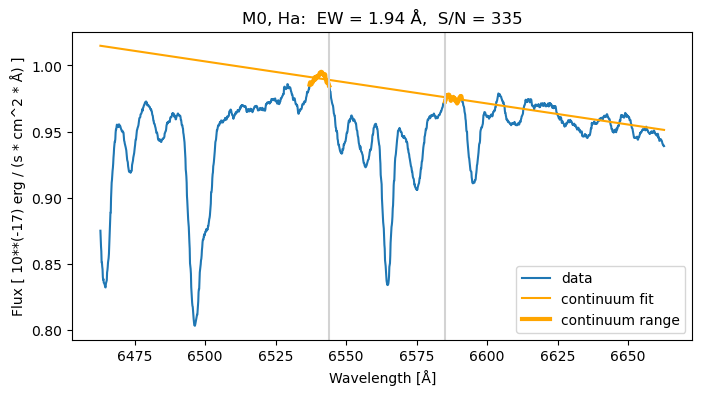

M0 Ha: flux = 1.9 *1e-17 erg/s/cm^2,  S/N = 334.7,  EW = 1.94 Å


1.9356371

In [146]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("M0", "Ha", cont_left=[6537,6544], cont_right=[6585,6591])

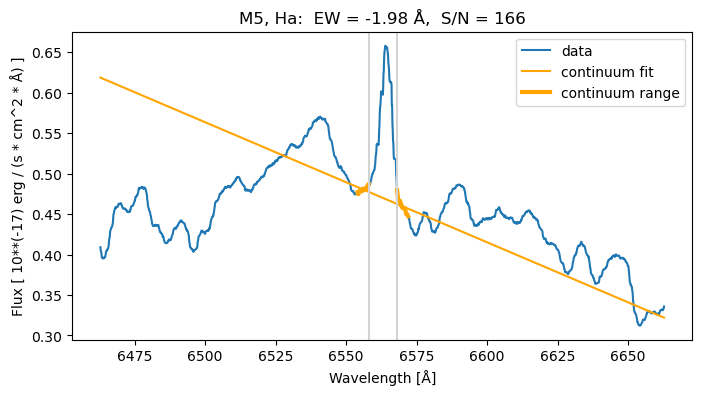

M5 Ha: flux = 0.93 *1e-17 erg/s/cm^2,  S/N = 165.9,  EW = -1.98 Å


-1.9831898

In [147]:
# Έλεγχος: πρέπει να δώσει το ίδιο EW με τα βήμα-βήμα κελιά παραπάνω
#measure_line("B0", "Ha")
measure_line("M5", "Ha", cont_left=[6554,6558], cont_right=[6568,6572])

O5 Ha: flux = 12.5 *1e-17 erg/s/cm^2,  S/N = 115.2,  EW = 5.23 Å
B0 Ha: flux = 11.4 *1e-17 erg/s/cm^2,  S/N = 130.1,  EW = 5.54 Å
B5 Ha: flux = 13.3 *1e-17 erg/s/cm^2,  S/N = 148.0,  EW = 6.57 Å
A0 Ha: flux = 16.4 *1e-17 erg/s/cm^2,  S/N = 88.6,  EW = 11.22 Å
A6 Ha: flux = 15.8 *1e-17 erg/s/cm^2,  S/N = 194.6,  EW = 9.54 Å
F0 Ha: flux = 12.7 *1e-17 erg/s/cm^2,  S/N = 379.9,  EW = 8.61 Å
F5 Ha: flux = 7.77 *1e-17 erg/s/cm^2,  S/N = 102.1,  EW = 4.97 Å
G0 Ha: flux = 5.77 *1e-17 erg/s/cm^2,  S/N = 222.8,  EW = 3.97 Å
G5 Ha: flux = 5.29 *1e-17 erg/s/cm^2,  S/N = 440.0,  EW = 3.76 Å
K0 Ha: flux = 4.67 *1e-17 erg/s/cm^2,  S/N = 297.6,  EW = 3.56 Å
K5 Ha: flux = 3.62 *1e-17 erg/s/cm^2,  S/N = 183.0,  EW = 3.04 Å
M0 Ha: flux = 1.9 *1e-17 erg/s/cm^2,  S/N = 334.7,  EW = 1.94 Å
M5 Ha: flux = 0.93 *1e-17 erg/s/cm^2,  S/N = 165.9,  EW = -1.98 Å
Equivalent Width of Hα:
 O5:   5.235 Å
 B0:   5.544 Å
 B5:   6.569 Å
 A0:  11.222 Å
 A6:   9.536 Å
 F0:   8.609 Å
 F5:   4.968 Å
 G0:   3.969 Å
 G5:   3.76

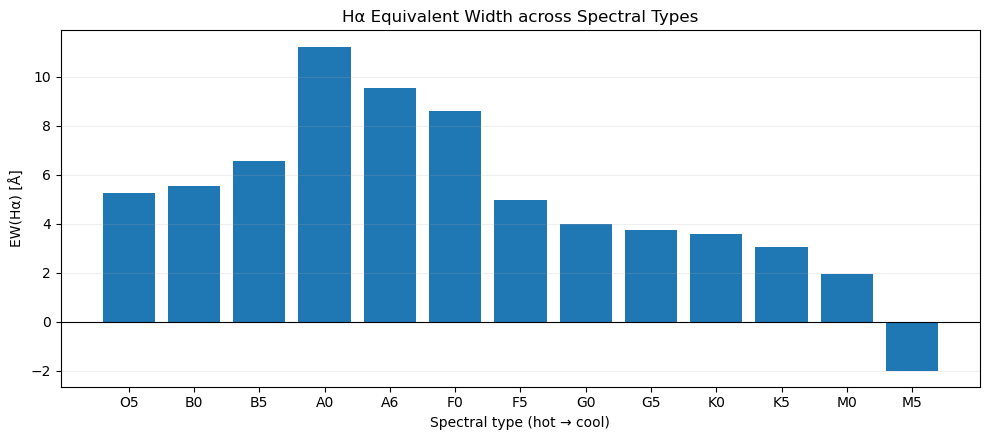

In [148]:

# EW της Hα για όλους τους φασματικούς τύπους
# Βελτιωμένα παράθυρα συνεχούς από οπτικό έλεγχο
# Ίδια ακριβώς μέθοδος υπολογισμού με το εργαστήριο

ha_windows = {
    "O5": ([6495, 6525], [6608, 6637]),
    "B0": ([6495, 6525], [6608, 6638]),
    "B5": ([6498, 6525], [6605, 6638]),
    "A0": ([6495, 6525], [6608, 6638]),
    "A6": ([6500, 6524], [6611, 6634]),
    "F0": ([6510, 6530], [6610, 6640]),
    "F5": ([6510, 6531], [6608, 6638]),
    "G0": ([6510, 6530], [6608, 6630]),
    "G5": ([6526, 6540], [6618, 6625]),
    "K0": ([6521, 6533], [6618, 6625]),
    "K5": ([6523, 6533], [6618, 6626]),
    "M0": ([6537, 6544], [6585, 6591]),
    "M5": ([6554, 6558], [6568, 6572])
}

# Υπολογισμός EW με την αρχική measure_line()
EW_Ha = {}

for star, (left, right) in ha_windows.items():
    EW_Ha[star] = measure_line(
        star,
        "Ha",
        cont_left=left,
        cont_right=right,
        plot=False
    )

# Εκτύπωση αποτελεσμάτων
print("Equivalent Width of Hα:")
for star, ew in EW_Ha.items():
    print(f"{star:>3s}: {ew:7.3f} Å")

# Διάγραμμα EW ως συνάρτηση του φασματικού τύπου
plt.figure(figsize=(10, 4.5))

plt.bar(
    list(EW_Ha.keys()),
    list(EW_Ha.values())
)

plt.xlabel("Spectral type (hot → cool)")
plt.ylabel("EW(Hα) [Å]")
plt.title("Hα Equivalent Width across Spectral Types")

plt.axhline(0, color="black", linewidth=0.8)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


In [149]:
# Ερωτηματα άσκησης

# 1) κάντε την μέτρηση του EW της Ηα για όλα τα αστέρια και βρείτε σε ποιό είναι μέγιστη.
# 2) για τον αστέρα F0, χρησιμοποιείστε τα EW της Hδ (n=2->6) και της Paschen 3->7 για να υπολογίσετε τη θερμοκρασία του αστέρα.
#     Συγκρίνετε τη θερμοκρασία που βγάλατε με αυτή του μελανου σώματος που περιγράφει τη συνεχή εκπομπή στο παρακάτω σχημα.

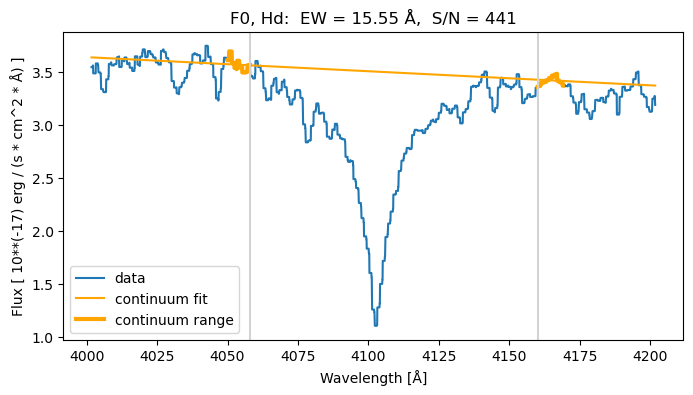

F0 Hd: flux = 54.4 *1e-17 erg/s/cm^2,  S/N = 440.6,  EW = 15.55 Å


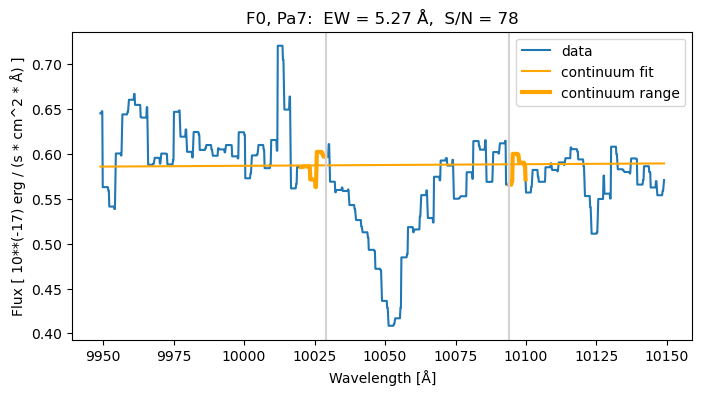

F0 Pa7: flux = 3.1 *1e-17 erg/s/cm^2,  S/N = 78.0,  EW = 5.27 Å

Hδ:  EW = 15.552 Å
Paδ: EW = 5.272 Å


In [150]:

# Ερώτημα 2: Hδ και Paδ στον αστέρα F0
# Ίδια μέθοδος εργαστηρίου - προσεκτικότερα παράθυρα συνεχούς

EW_Hd = measure_line(
    "F0", "Hd",
    cont_left=[4050, 4058],
    cont_right=[4160, 4169]
)

EW_Pa7 = measure_line(
    "F0", "Pa7",
    cont_left=[10020, 10029],
    cont_right=[10094, 10100]
)

print(f"\nHδ:  EW = {EW_Hd:.3f} Å")
print(f"Paδ: EW = {EW_Pa7:.3f} Å")


In [151]:

# Θερμοκρασία διέγερσης από Hδ / Paδ
# Υπόθεση: και οι δύο γραμμές βρίσκονται
# στο γραμμικό τμήμα της καμπύλης αύξησης

lam_Hd = 4101.7
lam_Pa = 10049.0

f_Hd = 0.0221
f_Pa = 0.0277

k_B = 8.617333262e-5  # eV/K

# Λόγος πληθυσμών κατώτερων σταθμών
N2_N3 = (
    (EW_Hd / EW_Pa7)
    * (f_Pa / f_Hd)
    * (lam_Pa / lam_Hd)**2
)

# Ενεργειακές στάθμες του υδρογόνου
E2 = 13.6 * (1 - 1/2**2)
E3 = 13.6 * (1 - 1/3**2)

# Στατιστικά βάρη
g2 = 2 * 2**2
g3 = 2 * 3**2

# Εξίσωση Boltzmann
T_exc = (E3 - E2) / (
    k_B * np.log(N2_N3 * g3 / g2)
)

T_eff = 7400  # K, τιμή αναφοράς φυλλαδίου

print(f"N2/N3 = {N2_N3:.3f}")
print(f"T_exc = {T_exc:.0f} K")
print(f"T_eff(reference) = {T_eff} K")
print(f"Difference = {T_exc - T_eff:.0f} K")


N2/N3 = 22.193
T_exc = 5605 K
T_eff(reference) = 7400 K
Difference = -1795 K


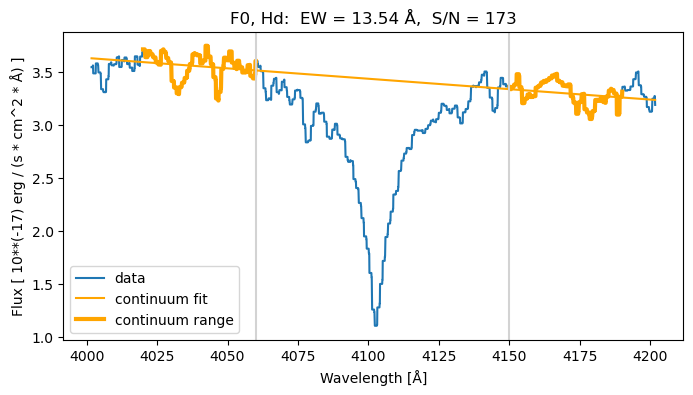

F0 Hd: flux = 46.5 *1e-17 erg/s/cm^2,  S/N = 173.2,  EW = 13.54 Å


In [152]:
# Ερώτημα 2: μία κλήση της συνάρτησης για κάθε γραμμή
EW_Hd = measure_line("F0", "Hd")
# EW_Pa7 = measure_line("F0", "Pa7")

In [153]:
# Φυσικές σταθερές και παράμετροι του οδηγού
lambda_Hd, lambda_Pa = 4101.7, 10049.0  # Å
osc_Hd, osc_Pa = 0.0221, 0.0277
kB_eV = 8.617333262e-5                  # eV/K
E2 = 13.6*(1-1/2**2)                    # eV
aE = 13.6*(1/2**2 - 1/3**2)              # E3-E2, eV
E3 = E2+aE
g2, g3 = 2*2**2, 2*3**2

N2_N3 = (EW_Hd/EW_Pa7)*(osc_Pa/osc_Hd)*(lambda_Pa/lambda_Hd)**2
Q = N2_N3*(g3/g2)
if Q <= 1:
    raise ValueError("Μη φυσικό αποτέλεσμα για θετική T — ελέγξτε τα EW")
T_exc = aE/(kB_eV*np.log(Q))

# Υπό ανεξάρτητες τυπικές αβεβαιότητες EW:
relN = np.hypot(f0_Hd["sigma_formal"]/EW_Hd,
                f0_Pa["sigma_formal"]/EW_Pa7)
sigma_ratio = N2_N3*relN
sigma_T_formal = T_exc/np.log(Q)*relN

print(f"E2={E2:.4f} eV, E3={E3:.4f} eV, ΔE={aE:.4f} eV")
print(f"g2={g2}, g3={g3}, N2/N3={N2_N3:.3f} ± {sigma_ratio:.3f} (τυπική)")
print(f"T_exc={T_exc:.0f} ± {sigma_T_formal:.0f} K (μόνο τυπικό σφάλμα)")
print(f"log10(W_Hδ/λ_Hδ)={np.log10(EW_Hd/lambda_Hd):.3f}")
print(f"log10(W_Paδ/λ_Paδ)={np.log10(EW_Pa7/lambda_Pa):.3f}")

# Εύρος T για συνδυασμούς των κοντινών εναλλακτικών παραθύρων
hmin,hmax = W_ranges["Hd"]
pmin,pmax = W_ranges["Pa7"]
def excitation_T(W_Hd,W_Pa):
    ratio=(W_Hd/W_Pa)*(osc_Pa/osc_Hd)*(lambda_Pa/lambda_Hd)**2
    return aE/(kB_eV*np.log(ratio*g3/g2))
t_sens = [excitation_T(h,p) for h in (hmin,hmax) for p in (pmin,pmax)]
print(f"Ευαισθησία παραθύρων: T ≈ {min(t_sens):.0f}–{max(t_sens):.0f} K")

# ΑΝΕΞΑΡΤΗΤΗ σύγκριση με θερμοκρασία αναφοράς, όχι fitting της θερμοκρασίας
print("T_eff (φυλλάδιο, F0): ~7400 K")
print("T_eff (FITs/λεξικό του οδηγού, εφόσον υπάρχει):",stars.get('F0'),"K")

E2=10.2000 eV, E3=12.0889 eV, ΔE=1.8889 eV
g2=8, g3=18, N2/N3=19.324 ± 0.575 (τυπική)
T_exc=5811 ± 46 K (μόνο τυπικό σφάλμα)
log10(W_Hδ/λ_Hδ)=-2.481
log10(W_Paδ/λ_Paδ)=-3.280


NameError: name 'W_ranges' is not defined

In [ ]:
import numpy as np

def f0_ew_uncertainty(star, line, left, right, halfwidth=100):
    x_all, y_all = spectra[star]
    center = lines[line]["lam"]
    use = (x_all >= center-halfwidth) & (x_all <= center+halfwidth)
    x = np.asarray(x_all[use], dtype=float)
    y = np.asarray(y_all[use], dtype=float)

    l = (x > left[0]) & (x < left[1])
    r = (x > right[0]) & (x < right[1])
    w = l | r
    line_mask = (x > left[1]) & (x < right[0])
    if min(l.sum(), r.sum(), line_mask.sum()) < 2:
        raise ValueError("Πολύ λίγα σημεία στα παράθυρα / στην ολοκλήρωση")

    # ΙΔΙΟ συνεχές και ολοκλήρωμα με τη measure_line()
    xL, xR = np.mean(left), np.mean(right)
    yL, yR = y[l].mean(), y[r].mean()
    continuum = yL + (yR-yL)*(x-xL)/(xR-xL)
    dlambda = np.gradient(x)
    EW = np.sum((1-y[line_mask]/continuum[line_mask])*dlambda[line_mask])
    F = abs(np.sum((y[line_mask]-continuum[line_mask])*dlambda[line_mask]))
    sigma_pixel = np.std(y[w]-continuum[w], ddof=1)
    SN = F/(np.sqrt(line_mask.sum())*np.std(y[w]-continuum[w])*np.mean(dlambda[w]))

    # Τυπικό σφάλμα EW από τυχαίο θόρυβο στα pixels
    sigma_W_noise = np.sqrt(np.sum(
        (sigma_pixel*dlambda[line_mask]/continuum[line_mask])**2))

    # Επίδραση των αβεβαιοτήτων στη μέση ροή των ΔΥΟ παραθύρων
    alpha = (xR-x[line_mask])/(xR-xL)
    beta = 1-alpha
    dW_dyL = np.sum(y[line_mask]*dlambda[line_mask]*alpha / continuum[line_mask]**2)
    dW_dyR = np.sum(y[line_mask]*dlambda[line_mask]*beta / continuum[line_mask]**2)
    sigma_yL = np.std(y[l]-continuum[l],ddof=1)/np.sqrt(l.sum())
    sigma_yR = np.std(y[r]-continuum[r],ddof=1)/np.sqrt(r.sum())
    sigma_W_cont = np.hypot(dW_dyL*sigma_yL, dW_dyR*sigma_yR)
    sigma_W_formal = np.hypot(sigma_W_noise, sigma_W_cont)

    return dict(W=EW, F=F, SN=SN, N_left=int(l.sum()),
                N_right=int(r.sum()), sigma_noise=sigma_W_noise,
                sigma_cont=sigma_W_cont, sigma_formal=sigma_W_formal)

f0_Hd = f0_ew_uncertainty("F0", "Hd", *F0_windows["Hd"])
f0_Pa = f0_ew_uncertainty("F0", "Pa7", *F0_windows["Pa7"])
assert np.isclose(EW_Hd, f0_Hd["W"], atol=0.003)
assert np.isclose(EW_Pa7, f0_Pa["W"], atol=0.003)

for name, result in [("Hδ", f0_Hd), ("Paδ", f0_Pa)]:
    print(f'{name}: EW = {result["W"]:.3f} ± {result["sigma_formal"]:.3f} Å '
          f'(τυπική, χωρίς συστηματικά σφάλματα), S/N = {result["SN"]:.1f}, '
          f'N_cont = {result["N_left"]}+{result["N_right"]}')

In [ ]:
# Εναλλακτικά κοντινά παράθυρα, μόνο για διαγνωστικό έλεγχο
alternatives = {
    "Hd": [
        ([4050,4058], [4160,4169]),
        ([4051,4057], [4161,4168]),
        ([4050,4059], [4160,4168]),
        ([4051,4058], [4160,4169]),
        ([4048,4058], [4160,4169]),
    ],
    "Pa7": [
        ([10020,10029], [10094,10100]),
        ([10021,10029], [10094,10099]),
        ([10020,10027], [10094,10100]),
        ([10022,10030], [10094,10100]),
        ([10024,10029], [10094,10100]),
    ],
}
W_ranges = {}
for line_name, choices in alternatives.items():
    values = [f0_ew_uncertainty("F0", line_name, L, R)["W"]
              for L, R in choices]
    W_ranges[line_name] = (min(values), max(values))
    print(f"{line_name}: κοντινές επιλογές -> EW από "
          f"{min(values):.3f} ως {max(values):.3f} Å")


In [ ]:
# F0: Οι δύο μετρήσεις EW — ίδια συνάρτηση του εργαστηρίου
F0_windows = {
    "Hd":  ([4050, 4058], [4160, 4169]),
    "Pa7": ([10020, 10029], [10094, 10100]),
}

EW_Hd = measure_line("F0", "Hd",
    cont_left=F0_windows["Hd"][0],
    cont_right=F0_windows["Hd"][1], plot=True)
EW_Pa7 = measure_line("F0", "Pa7",
    cont_left=F0_windows["Pa7"][0],
    cont_right=F0_windows["Pa7"][1], plot=True)

print(f"Hδ:  EW = {EW_Hd:.3f} Å")
print(f"Paδ: EW = {EW_Pa7:.3f} Å")

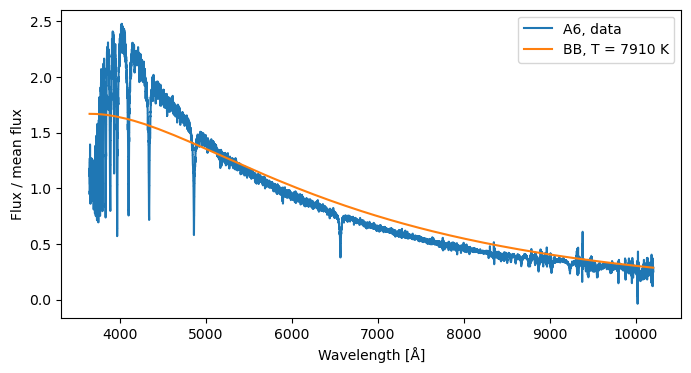

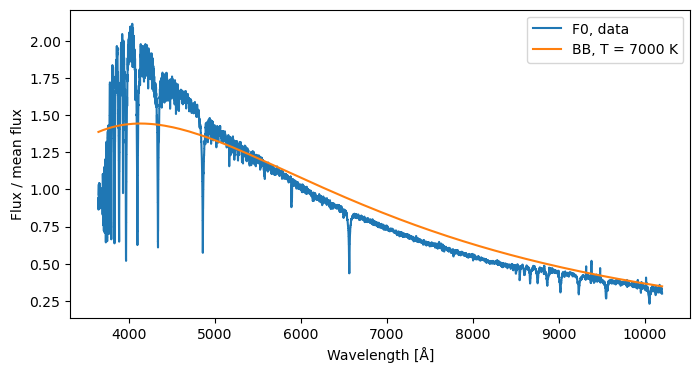

In [154]:
# Σύγκριση με θεωρητική τιμή BB

def black_body_luminosity(wavelength,T=1000): # wavelength in Angstrom
    h, c, kb = 6.626e-27, 2.9979e18, 1.381e-16    # erg s, Å/s, erg/K
    B_lambda = 2*h*c**2/ wavelength**5/(np.exp(h*c/(wavelength*kb*T))-1)
    return B_lambda/np.mean(B_lambda) # κανονικοποιημένο σχήμα (οι μονάδες δεν μας ενδιαφέρουν εδώ)

def plot_bb(star, T=None):
    # star: όνομα αστέρα      T: θερμοκρασία BB σε K. Αν δεν δοθεί, παίρνουμε τη θερμοκρασία αναφοράς stars[star]
    if T is None:
        T = stars[star]
    x = spectra[star][0]
    y = spectra[star][1]/np.mean(spectra[star][1])
    plt.figure(figsize=(8,4))
    plt.plot(x, y, label=star+", data")
    plt.plot(x, black_body_luminosity(x, T), label=f"BB, T = {T:.0f} K")
    plt.xlabel("Wavelength [Å]")
    plt.ylabel("Flux / mean flux")
    plt.legend()
    plt.show()

plot_bb("A6")             # με τη θερμοκρασία αναφοράς
plot_bb("F0", T=7000)   # καντε overplot ένα μελαν σωμα με την Τ που βρήκατε από τα EW των γραμμών του Η

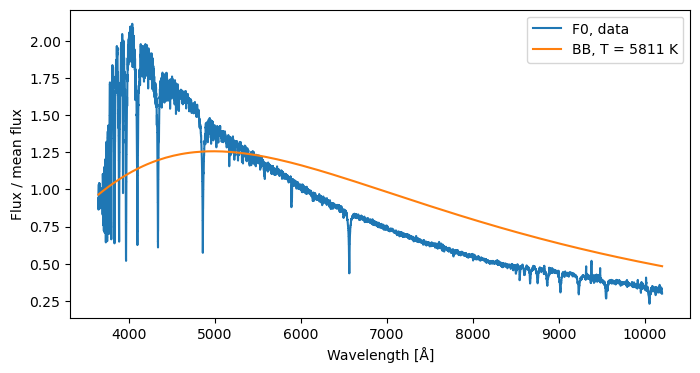

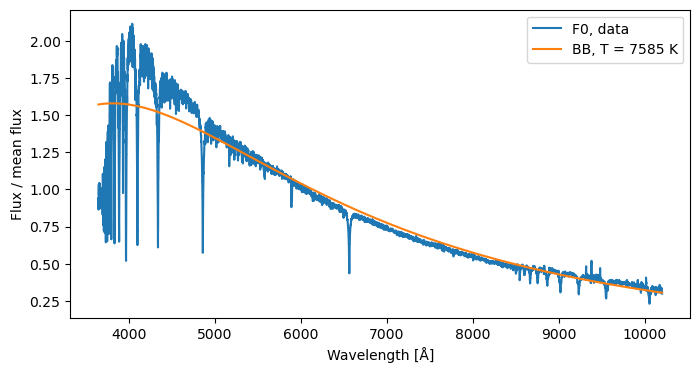

In [156]:
# Εκτέλεσέ το μόνο αφού εκτελέσεις το αρχικό κελί που ορίζει plot_bb
plot_bb("F0", T=T_exc)
plot_bb("F0", T=stars["F0"])

### EXTRA (προαιρετικό): θερμοκρασία από προσαρμογή μέλανος σώματος
Βρίσκουμε τη θερμοκρασία *T* του μέλανος σώματος που ταιριάζει καλύτερα στο συνεχές (4000–9000 Å) κάθε αστέρα και τη συγκρίνουμε με τη θερμοκρασία αναφοράς.
Ερώτηση: γιατί για τους αστέρες O και B η προσαρμογή δίνει πολύ μεγάλες (και αβέβαιες) θερμοκρασίες;

In [ ]:
T_grid = np.logspace(np.log10(2000), np.log10(50000), 500)   # δοκιμαστικές θερμοκρασίες (K)

for i in stars:
    x, y = spectra[i]
    m = (x > 4000) & (x < 9000)            # αφήνουμε έξω το άλμα Balmer (< 3650-4000 Å)
    chi2 = []
    for T in T_grid:
        B = black_body_luminosity(x[m], T)
        a = np.sum(y[m]*B)/np.sum(B*B)     # καλύτερη κανονικοποίηση για αυτή την T
        chi2.append(np.sum((y[m]-a*B)**2))
    T_fit = T_grid[np.argmin(chi2)]
    print(f"{i}:  T_BB = {T_fit:7.0f} K   T_ref = {stars[i]:6d} K")

# Πρόσθετος επιστημονικός έλεγχος Hα — 22/10/2026

**Δεν έχουν αλλάξει τα αρχικά κελιά.** Στα 13 φάσματα επιλέγουμε καθαρότερα παράθυρα συνεχούς *χειροκίνητα από τις μεγεθύνσεις*. 

**Προσοχή:** `measure_line` στο αρχικό notebook θέτει αυτομάτως όρια ολοκλήρωσης από το τέλος του αριστερού και την αρχή του δεξιού παραθύρου. Στους G/K/M, όταν χρησιμοποιούμε πιο μακρινά καθαρά παράθυρα, μπορεί έτσι να προσθέσουμε γειτονικές μεταλλικές/μοριακές γραμμές στο EW της Hα. Για τον λόγο αυτό δείχνουμε **και** (α) την αυθεντική εργαστηριακή μέθοδο **και** (β) την απομονωμένη περιοχή της Hα. Δεν βελτιστοποιούμε με στόχο μια αναμενόμενη θερμοκρασία ή EW.

Το M5 παρουσιάζει **εκπομπή** κοντά στην Hα, οπότε δεν το αντιμετωπίζουμε σαν συνηθισμένη γραμμή απορρόφησης. Αποτελέσματα για θερμοκρασία διέγερσης από Hδ/Paδ **δεν** εξάγονται από το παρόν τμήμα.


In [ ]:
# Προτεινόμενα παράθυρα με οπτικό έλεγχο (Å)
# Το τρίτο ζεύγος είναι ΜΟΝΟ η περιοχή ολοκλήρωσης της Hα.
ha_review = {'O5': ([6495, 6525], [6608, 6637], (6534, 6603)), 'B0': ([6495, 6525], [6608, 6638], (6535, 6604)), 'B5': ([6498, 6525], [6605, 6638], (6530, 6605)), 'A0': ([6495, 6525], [6608, 6638], (6528, 6608)), 'A6': ([6500, 6524], [6611, 6634], (6527, 6608)), 'F0': ([6510, 6530], [6610, 6640], (6533, 6609)), 'F5': ([6510, 6531], [6608, 6638], (6536, 6605)), 'G0': ([6510, 6530], [6608, 6630], (6543, 6587)), 'G5': ([6526, 6540], [6618, 6625], (6541, 6585)), 'K0': ([6521, 6533], [6618, 6625], (6545, 6582)), 'K5': ([6523, 6533], [6618, 6626], (6549, 6580)), 'M0': ([6537, 6544], [6585, 6591], (6554, 6572)), 'M5': ([6554, 6558], [6568, 6572], (6558, 6568))}

# Δοκίμασε χειροκίνητα άλλες τιμές και ξανατρέξε τα ακόλουθα κελιά.
# Διάστημα (l1,l2): δείγμα του συνεχούς αριστερά.
# Διάστημα (r1,r2): δείγμα του συνεχούς δεξιά.
# Διάστημα (i1,i2): αποκλειστικά το προφίλ Hα, χωρίς περιττές γειτονικές γραμμές.



In [ ]:
def ha_review_measure(star, continuum_left, continuum_right, integration=None, plot=True):
    x, flux = spectra[star]
    center = 6562.8
    selected = (x > center-120) & (x < center+120)
    x = x[selected]; flux = flux[selected]
    l1, l2 = continuum_left; r1, r2 = continuum_right
    left = (x>l1)&(x<l2); right=(x>r1)&(x<r2)
    if not (left.any() and right.any()):
        raise ValueError("Άδειο παράθυρο συνεχούς")
    x1, x2 = (l1+l2)/2, (r1+r2)/2
    f1, f2 = np.mean(flux[left]), np.mean(flux[right])
    continuum = f1+(f2-f1)*(x-x1)/(x2-x1)
    if integration is None:
        integration = (l2,r1)  # ακριβώς η σύμβαση του αρχικού notebook
    integ=(x>integration[0]) & (x<integration[1])
    dlambda=np.gradient(x)
    ew=np.sum((1-flux[integ]/continuum[integ])*dlambda[integ])
    total_flux=np.sum((continuum[integ]-flux[integ])*dlambda[integ])
    if plot:
        plt.figure(figsize=(10,3.7))
        plt.plot(x, flux, lw=1, label='FITS')
        plt.plot(x, continuum, '--', label='Γραμμικό συνεχές')
        plt.axvspan(l1,l2,alpha=.17,label='Αριστερό παράθυρο')
        plt.axvspan(r1,r2,alpha=.17,label='Δεξί παράθυρο')
        plt.axvspan(*integration,alpha=.08,label='Όρια ολοκλήρωσης Hα')
        plt.axvline(center,lw=.6,ls=':')
        plt.xlim(6480 if star not in ('M0','M5') else 6530,
                 6650 if star not in ('M0','M5') else 6610)
        plt.title(f'{star}  EW(Hα)={ew:.3f} Å');plt.xlabel('λ [Å]')
        plt.ylabel('fλ [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]');plt.legend(fontsize=8)
        plt.tight_layout();plt.show()
    return ew, total_flux

# Π.χ. αναλυτικός οπτικός έλεγχος μόνο του A0
ha_review_measure('A0', *ha_review['A0'][:2], integration=ha_review['A0'][2])


In [ ]:
# Ακριβής αναπαραγωγή της αρχικής συνάρτησης ΜΕ τα αναθεωρημένα παράθυρα
ha_ew_original_method={}
ha_ew_isolated={}
for star in ha_review:
    left, right, integration=ha_review[star]
    ha_ew_original_method[star] = measure_line(star,'Ha',cont_left=left,cont_right=right,plot=False)
    ha_ew_isolated[star],_=ha_review_measure(star,left,right,integration=integration,plot=False)
    print(f'{star:>2s}:  original-limits EW={ha_ew_original_method[star]:7.3f} Å,  Hα-only EW={ha_ew_isolated[star]:7.3f} Å')

# Τελικό plot, με χωριστή διάκριση του M5 (γραμμή εκπομπής)
labels=list(ha_review)
plt.figure(figsize=(11,4.5))
plt.plot(labels,[ha_ew_original_method[k] for k in labels],'o--',label='Παράθυρα = όρια ολοκλήρωσης')
plt.plot(labels,[ha_ew_isolated[k] for k in labels],'s-',label='Μόνο Hα: ανεξάρτητα όρια ολοκλήρωσης')
plt.axhline(0,lw=.8)
plt.ylabel('EW(Hα) [Å]');plt.xlabel('Φασματικός τύπος')
plt.title('Επίδραση επιλογής συνεχούς / ορίων ολοκλήρωσης')
plt.legend();plt.grid(alpha=.2);plt.tight_layout();plt.show()


In [ ]:
# Zoom όλα τα φάσματα: επανέλεγχος παραθύρων με το μάτι
for star,(left,right,integration) in ha_review.items():
    ha_review_measure(star,left,right,integration=integration,plot=True)



## Για την επόμενη φάση της εργασίας
1. Προσαρμόζουμε τελικά τα παράθυρα της **Hδ** (4101,7 Å) και της **Paδ** (10049 Å) ειδικά στον F0. 
2. Μετράμε EW, S/N, αβεβαιότητες με διακύμανση επιλογής συνεχούς, και εξετάζουμε **καμπύλη αύξησης**. 
3. Υπολογίζουμε τον λόγο πληθυσμών N₂/N₃ και *μόνο υπό τις κατάλληλες παραδοχές* τη θερμοκρασία διέγερσης μέσω Boltzmann. 
4. Συγκρίνουμε με αναμενόμενο T_eff(F0) ≈ 7400 K και γράφουμε την αναφορά έως 2 σελίδες, χωρίς θεωρητική εισαγωγή.

